# Chapter 13: Introducing Automatic Optimization: *Let's Build a Deep Learning Framework*

### Target pembelajaran
Setelah mengerjakan notebook ini, pembaca diharapkan mampu:
1. Menjelaskan peran *tensor*, *dynamic computation graph*, dan **automatic differentiation** (*autograd*).
2. Membuktikan aturan turunan lokal untuk penjumlahan, perkalian, reduksi, perkalian matriks, dan fungsi aktivasi.
3. Mengimplementasikan `Tensor` dan `.backward()` dari awal dengan **NumPy**, lalu menguji gradien secara numerik.
4. Membuat `SGD`, `Layer`, `Linear`, `Sequential`, `MSELoss`, `Tanh`, `Sigmoid`, `Embedding`, `CrossEntropyLoss`, dan `RNNCell`.
5. Menggunakan framework mini untuk pembelajaran terawasi sederhana dan prediksi kata dari konteks (*sequence modeling*).

## 1. Mengapa deep learning membutuhkan framework? 

Pada Bab 3–12, turunan untuk tiap jaringan saraf dikodekan secara manual. Ini mengajarkan cara kerja model, tetapi menimbulkan tiga persoalan teknik: (1) kode untuk *backpropagation* mudah salah, (2) pergantian arsitektur memerlukan perhitungan gradien baru, dan (3) pembaruan parameter tersebar dalam kode.

**Framework** memisahkan tiga tanggung jawab:

| Komponen | Peran |
|---|---|
| `Tensor` dan operasi numerik | Menampung data serta membangun relasi antaroperasi |
| `autograd` | Menghitung gradien parameter secara otomatis dari *loss* |
| `Layer` / `Optimizer` | Menyusun blok model dan memperbarui bobot secara konsisten |

Kerangka alur: **input → forward → loss → backward → optimizer.step()**. Framework tidak otomatis membuat model lebih akurat; ia mempermudah implementasi, pengujian, dan eksplorasi model.

**Batasan:** Implementasi edukatif ini berjalan di CPU, belum menyediakan operasi GPU, *mixed precision*, kompilasi graf, ataupun pemeriksaan numerik lengkap yang dimiliki framework industri.

## 2. Tensor: generalisasi skalar, vektor, dan matriks 

Tensor adalah array berdimensi $n$. **Rank** menunjukkan jumlah sumbu: skalar rank-0, vektor rank-1, matriks rank-2, dan seterusnya. `shape` menyatakan panjang di tiap sumbu. Dalam notebook ini `Tensor.data` menampung `np.ndarray`, sedangkan `Tensor.grad` menampung gradien jika parameter perlu dipelajari.

Perhatikan bahwa **tensor bukan neural network**: tensor adalah struktur data dengan operasi matematika yang nantinya digunakan jaringan.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 13
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=5, suppress=True)

contoh = [np.array(2.), np.array([1., 2., 3.]), np.zeros((2, 3)), np.zeros((2, 3, 4))]
for a in contoh:
    print(f"shape={str(a.shape):>9}, ndim={a.ndim}, size={a.size}")

shape=       (), ndim=0, size=1
shape=     (3,), ndim=1, size=3
shape=   (2, 3), ndim=2, size=6
shape=(2, 3, 4), ndim=3, size=24


## 3. *Dynamic computation graph* dan prinsip *chain rule* 

Setiap operasi membentuk hubungan **anak → pembuatnya** dalam graf komputasi. Contoh:

$$z = (a+b)\times c.$$

Setelah perhitungan maju, relasi `z ← (a+b), c` tersimpan. Untuk $L=z$ dan variabel skalar, aturan rantai menghasilkan:

$$\frac{\partial L}{\partial a}=c,\quad
\frac{\partial L}{\partial b}=c,\quad
\frac{\partial L}{\partial c}=a+b.$$

**Reverse-mode autodiff:** mulai dari $\partial L/\partial L=1$, kunjungi operasi berurutan dari keluaran ke masukan, lalu jumlahkan kontribusi turunan dari seluruh jalur.

**Masalah *multiuse*:** bila $f = (a+b)+(b+c)$, variabel $b$ dipakai dua kali, maka $\partial f/\partial b=2$, **bukan** 1. Buku menyelesaikannya dengan pelacakan `children`; implementasi ini memakai **urutan topologis terbalik**, sehingga suatu simpul diproses setelah semua kontribusi turunannya terkumpul. Kedua pendekatan menerapkan prinsip matematika yang sama.

## 4. Implementasi inti kelas `Tensor` dan autograd 

Untuk setiap operasi, kita definisikan (i) hasil numerik saat *forward* dan (ii) *fungsi lokal* untuk mengirim gradien balik. `Tensor.creators` menyimpan parent sehingga *reverse traversal* bisa dilakukan secara otomatis.

**Perbedaan eksplisit dari kode buku:** atribut `.grad` berisi `np.ndarray` (bukan objek `Tensor`); operator aritmetika juga mendukung *broadcasting*, tetapi `mm` sengaja dibatasi pada matriks rank-2 supaya bentuk gradien mudah diperiksa. Ini adalah pilihan rekayasa, bukan perubahan teori.

In [2]:
def _unbroadcast(grad, shape):
    """Jumlahkan gradien pada dimensi yang muncul karena broadcasting NumPy."""
    g = np.asarray(grad, dtype=float)
    while g.ndim > len(shape):
        g = g.sum(axis=0)
    for axis, size in enumerate(shape):
        if size == 1 and g.shape[axis] != 1:
            g = g.sum(axis=axis, keepdims=True)
    return g.reshape(shape)


class Tensor:
    """Tensor minimal dengan reverse-mode automatic differentiation."""

    def __init__(self, data, autograd=False, creators=(), creation_op=None):
        self.data = np.array(data)
        self.autograd = bool(autograd)
        self.creators = tuple(creators)
        self.creation_op = creation_op
        self.grad = None                   # gradien disimpan sebagai ndarray
        self._backward = lambda: None      # aturan turunan lokal diisi oleh operator

    def __repr__(self):
        return f"Tensor({self.data!r}, autograd={self.autograd})"

    def __str__(self):
        return str(self.data)

    @staticmethod
    def _to_tensor(other):
        return other if isinstance(other, Tensor) else Tensor(other)

    def _add_grad(self, grad):
        if self.autograd:
            g = np.asarray(grad, dtype=float)
            if g.shape != self.data.shape:
                raise ValueError(f"Gradien {g.shape} tidak cocok dengan {self.data.shape}")
            self.grad = g.copy() if self.grad is None else self.grad + g

    def backward(self, grad=None):
        """Urutkan graf lalu terapkan reverse-mode chain rule tepat satu kali/node."""
        if not self.autograd:
            raise ValueError("Tensor ini tidak memerlukan autograd")
        if grad is None:
            if self.data.size != 1:
                raise ValueError("Untuk keluaran nonskalar, berikan gradien awal")
            grad = np.ones_like(self.data, dtype=float)
        elif isinstance(grad, Tensor):
            grad = grad.data

        order, visited = [], set()

        def visit(t):
            if id(t) in visited:
                return
            visited.add(id(t))
            for parent in t.creators:
                visit(parent)
            order.append(t)

        visit(self)
        # Antarpemanggilan backward hasil dihitung dari nol agar demonstrasi deterministik.
        for node in order:
            node.grad = None
        self._add_grad(grad)
        for node in reversed(order):
            if node.grad is not None:
                node._backward()

    def __add__(self, other):
        other = self._to_tensor(other)
        out = Tensor(self.data + other.data,
                     self.autograd or other.autograd, (self, other), 'add')
        def local_backward():
            self._add_grad(_unbroadcast(out.grad, self.data.shape))
            other._add_grad(_unbroadcast(out.grad, other.data.shape))
        out._backward = local_backward
        return out

    __radd__ = __add__

    def __neg__(self):
        out = Tensor(-self.data, self.autograd, (self,), 'neg')
        out._backward = lambda: self._add_grad(-out.grad)
        return out

    def __sub__(self, other):
        return self + (-self._to_tensor(other))

    def __rsub__(self, other):
        return self._to_tensor(other) - self

    def __mul__(self, other):
        other = self._to_tensor(other)
        out = Tensor(self.data * other.data,
                     self.autograd or other.autograd, (self, other), 'mul')
        def local_backward():
            self._add_grad(_unbroadcast(out.grad * other.data, self.data.shape))
            other._add_grad(_unbroadcast(out.grad * self.data, other.data.shape))
        out._backward = local_backward
        return out

    __rmul__ = __mul__

    def sum(self, dim=None):
        out = Tensor(self.data.sum(axis=dim), self.autograd, (self,), 'sum')
        def local_backward():
            if dim is None:
                g = np.broadcast_to(out.grad, self.data.shape)
            else:
                g = np.broadcast_to(np.expand_dims(out.grad, axis=dim), self.data.shape)
            self._add_grad(g)
        out._backward = local_backward
        return out

    def expand(self, dim, copies):
        expanded = np.repeat(np.expand_dims(self.data, axis=dim), copies, axis=dim)
        out = Tensor(expanded, self.autograd, (self,), 'expand')
        out._backward = lambda: self._add_grad(out.grad.sum(axis=dim))
        return out

    def transpose(self):
        out = Tensor(self.data.transpose(), self.autograd, (self,), 'transpose')
        out._backward = lambda: self._add_grad(out.grad.transpose())
        return out

    def mm(self, other):
        other = self._to_tensor(other)
        if self.data.ndim != 2 or other.data.ndim != 2:
            raise ValueError("mm dalam framework mini ini khusus matriks 2D")
        out = Tensor(self.data @ other.data,
                     self.autograd or other.autograd, (self, other), 'mm')
        def local_backward():
            self._add_grad(out.grad @ other.data.T)
            other._add_grad(self.data.T @ out.grad)
        out._backward = local_backward
        return out

    def sigmoid(self):
        s = 1. / (1. + np.exp(-np.clip(self.data, -60, 60)))
        out = Tensor(s, self.autograd, (self,), 'sigmoid')
        out._backward = lambda: self._add_grad(out.grad * s * (1. - s))
        return out

    def tanh(self):
        h = np.tanh(self.data)
        out = Tensor(h, self.autograd, (self,), 'tanh')
        out._backward = lambda: self._add_grad(out.grad * (1. - h * h))
        return out

    def index_select(self, indices):
        ix = indices.data if isinstance(indices, Tensor) else np.asarray(indices)
        ix = np.asarray(ix, dtype=int)
        out = Tensor(self.data[ix], self.autograd, (self,), 'index_select')
        def local_backward():
            g = np.zeros_like(self.data, dtype=float)
            np.add.at(g, ix, out.grad)  # indeks berulang harus dijumlahkan, bukan ditimpa
            self._add_grad(g)
        out._backward = local_backward
        return out

    def cross_entropy(self, targets):
        """Softmax + mean negative log-likelihood dengan propagasi gradien stabil."""
        y = targets.data if isinstance(targets, Tensor) else np.asarray(targets)
        y = np.asarray(y, dtype=int).reshape(-1)
        if self.data.ndim != 2 or self.data.shape[0] != len(y):
            raise ValueError("Logits harus (batch, classes) dan target berukuran batch")
        logits = self.data.astype(float)
        shifted = logits - logits.max(axis=1, keepdims=True)
        exp = np.exp(shifted)
        probs = exp / exp.sum(axis=1, keepdims=True)
        logsumexp = np.log(exp.sum(axis=1))
        loss = (logsumexp - shifted[np.arange(len(y)), y]).mean()
        out = Tensor(loss, self.autograd, (self,), 'cross_entropy')
        def local_backward():
            dx = probs.copy()
            dx[np.arange(len(y)), y] -= 1.0
            dx /= len(y)             # wajib karena loss = MEAN, bukan sum
            self._add_grad(dx * out.grad)
        out._backward = local_backward
        return out

print('Tensor dan operasi autograd utama siap digunakan.')

Tensor dan operasi autograd utama siap digunakan.


## 5. Memeriksa *forward* dan graf operasi 

Untuk tensor dengan `autograd=True`, setiap hasil operasi menyimpan tipe operasi (`creation_op`) dan tautan ke pembuatnya (`creators`). Pada implementasi ini **graf dibangun bersamaan dengan komputasi forward**.

In [3]:
a = Tensor([1., 2., 3.], autograd=True)
b = Tensor([4., 5., 6.], autograd=True)
z = a + b
print('a + b =', z.data)
print('Operasi:', z.creation_op)
print('Jumlah parent:', len(z.creators))
print('Graf:', [node.data.tolist() for node in z.creators])
assert np.array_equal(z.data, [5., 7., 9.])

a + b = [5. 7. 9.]
Operasi: add
Jumlah parent: 2
Graf: [[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]]


## 6. Akumulasi gradien: tensor yang dipakai berkali-kali 

Misalkan $L=\sum_i[(a_i+b_i)+(b_i+c_i)]$. Karena $b_i$ muncul **dua kali**, $\partial L/\partial b_i=2$. Mengganti gradien lama dengan yang baru menghasilkan jawaban salah. Solusinya adalah **menjumlahkan** seluruh kontribusi gradien sebelum memproses simpulnya.

In [4]:
a = Tensor(np.array([1., 2., 3.]), autograd=True)
b = Tensor(np.array([2., 2., 2.]), autograd=True)
c = Tensor(np.array([3., 2., 1.]), autograd=True)
loss = ((a + b) + (b + c)).sum()
loss.backward()
print('grad a =', a.grad)
print('grad b =', b.grad, '<- muncul dua kali')
print('grad c =', c.grad)
assert np.allclose(a.grad, 1.)
assert np.allclose(b.grad, 2.)
assert np.allclose(c.grad, 1.)

grad a = [1. 1. 1.]
grad b = [2. 2. 2.] <- muncul dua kali
grad c = [1. 1. 1.]


## 7. Aturan turunan lokal untuk setiap operasi 

Dalam tabel ini, $G$ adalah gradien yang diterima sebuah operasi dari keluaran akhirnya.

| Forward | Gradien terhadap input |
|---|---|
| $z=a+b$ | $G_a=G$, $G_b=G$ |
| $z=-a$ | $G_a=-G$ |
| $z=a-b$ | $G_a=G$, $G_b=-G$ |
| $z=a\odot b$ | $G_a=G\odot b$, $G_b=G\odot a$ |
| $Z=AB$ | $G_A=G_ZB^T$, $G_B=A^TG_Z$ |
| $z=\sum_k a_k$ | Setiap elemen yang dijumlahkan menerima gradien yang sama |
| $z=\mathrm{tanh}(a)$ | $G_a=G(1-\tanh^2(a))$ |
| $z=\sigma(a)$ | $G_a=G\sigma(a)(1-\sigma(a))$ |

`expand` menambahkan dimensi dengan mengulang nilai; gradiennya perlu dijumlahkan di dimensi yang diulang. `transpose` menukar sumbu; pada *backward* sumbunya ditukar kembali. Perkalian elemen (*Hadamard product*) bukan sama dengan perkalian matriks.

**Catatan:** Jika suatu operasi memakai *broadcasting*, gradien terhadap tensor yang lebih kecil harus **direduksi** kembali ke bentuk aslinya (`_unbroadcast`).

In [5]:
# Menelusuri beberapa operasi yang diperkenalkan berurutan di buku.
x = Tensor([[1., 2., 3.], [4., 5., 6.]], autograd=True)
y = x.sum(dim=1)            # (2,3) -> (2,)
w = y.expand(dim=1, copies=3)  # (2,) -> (2,3)
f = w.sum()
f.backward()
print('x.sum(1):', y.data, '| shape', y.data.shape)
print('Hasil expand:', w.data)
print('grad x:', x.grad)
assert np.allclose(x.grad, 3.0)

p = Tensor(np.array([[1., 2.], [3., 4.]]), autograd=True)
q = Tensor(np.array([[0.5], [1.5]]), autograd=True)
(p.mm(q)).sum().backward()
print('grad p dari mm:', p.grad)
print('grad q dari mm:', q.grad)
assert p.grad.shape == p.data.shape and q.grad.shape == q.data.shape

x.sum(1): [ 6. 15.] | shape (2,)
Hasil expand: [[ 6.  6.  6.]
 [15. 15. 15.]]
grad x: [[3. 3. 3.]
 [3. 3. 3.]]
grad p dari mm: [[0.5 1.5]
 [0.5 1.5]]
grad q dari mm: [[4.]
 [6.]]


## 8. *Gradient checking*: menguji implementasi, bukan sekadar mempercayainya

Autograd menghasilkan gradien analitis. Independennya, kita dapat mendekati gradien melalui **beda hingga terpusat**:

$$\frac{\partial L}{\partial \theta_i}\approx\frac{L(\theta_i+\varepsilon)-L(\theta_i-\varepsilon)}{2\varepsilon},\quad\varepsilon=10^{-5}.$$

Jika kedua metode sangat dekat pada input non-ekstrem, implementasi turunan lebih mungkin benar. Pengujian numerik **tidak membuktikan semua kasus benar** (misalnya titik tidak diferensiabel, overflow, dan bentuk array lain), tetapi membantu mendeteksi kesalahan tanda, transpose, serta faktor ukuran batch.

In [6]:
def numerical_gradient(f, x, eps=1e-5):
    """f menerima ndarray, mengembalikan satu skalar float."""
    base = np.array(x, dtype=float, copy=True)
    result = np.zeros_like(base)
    for index in np.ndindex(base.shape):
        plus = base.copy(); minus = base.copy()
        plus[index] += eps; minus[index] -= eps
        result[index] = (f(plus) - f(minus)) / (2 * eps)
    return result

W0 = np.array([[0.2, -0.3], [0.4, 0.1]])
X = np.array([[1.0, -2.0], [0.5, 1.5], [-1., 0.1]])
T = np.array([0, 1, 1])

def f_array(W):
    v = np.tanh(X @ W)
    q = v - np.max(v, axis=1, keepdims=True)
    return float(np.mean(-q[np.arange(len(T)), T] + np.log(np.exp(q).sum(axis=1))))

W = Tensor(W0, autograd=True)
loss = Tensor(X).mm(W).tanh().cross_entropy(T)
loss.backward()
g_numeric = numerical_gradient(f_array, W0)
print('Gradien autodiff:\n', W.grad)
print('Gradien numerik:\n', g_numeric)
print('Galat maksimum:', np.max(np.abs(W.grad - g_numeric)))
assert np.allclose(W.grad, g_numeric, atol=1e-6, rtol=1e-5)

# Gradien 'multiuse' juga diuji langsung.
u = Tensor([0.7, -0.2], autograd=True)
(u * u + u).sum().backward()
assert np.allclose(u.grad, 2 * u.data + 1)

Gradien autodiff:
 [[-0.18045  0.14563]
 [ 0.46389 -0.60704]]
Gradien numerik:
 [[-0.18045  0.14563]
 [ 0.46389 -0.60704]]
Galat maksimum: 2.6766533434141593e-11


## 9. Melatih model pertama hanya dengan autograd

Buku memulai dengan 4 sampel input biner dan target berupa kolom kedua. Ini adalah tugas *supervised regression* kecil. Jaringan terdiri atas **dua transformasi linear berurutan**, dan menggunakan **sum of squared errors** (SSE):

$$\hat{Y}=XW_1W_2,\quad L=\sum_{i}(\hat{y}_i-y_i)^2.$$

Dengan autograd, tidak perlu lagi menulis rumus gradien terpisah untuk $W_1$ dan $W_2$. Tugas sederhana ini bukan bukti keberhasilan pada permasalahan yang kompleks.

In [7]:
X_data = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_data = np.array([[0.], [1.], [0.], [1.]])
X = Tensor(X_data)
y = Tensor(y_data)

w1 = Tensor(rng.normal(0, 0.35, size=(2, 3)), autograd=True)
w2 = Tensor(rng.normal(0, 0.35, size=(3, 1)), autograd=True)
loss_awal = None
riwayat_manual = []
for epoch in range(100):
    pred = X.mm(w1).mm(w2)
    error = pred - y
    loss = (error * error).sum()
    if loss_awal is None:
        loss_awal = float(loss.data)
    loss.backward()
    riwayat_manual.append(float(loss.data))
    for w in (w1, w2):
        w.data -= 0.1 * w.grad
print(f'Loss epoch pertama = {loss_awal:.6f}; epoch terakhir = {riwayat_manual[-1]:.6f}')
print('Prediksi akhir:', X.mm(w1).mm(w2).data.reshape(-1))
assert riwayat_manual[-1] < loss_awal

Loss epoch pertama = 1.565815; epoch terakhir = 0.000000
Prediksi akhir: [0. 1. 0. 1.]


## 10. Optimizer `SGD`: memisahkan pembaruan bobot 

**Stochastic gradient descent (SGD)** melakukan pembaruan parameter $\theta\leftarrow\theta-\alpha\nabla_\theta L$, dengan $\alpha$ *learning rate*. Kata *stochastic* menunjukkan praktik pembaruan dari sampel atau *minibatch* acak; persamaan yang sama juga dapat digunakan pada **full-batch** seperti contoh notebook ini. Pada setiap iterasi, gradien perlu disiapkan ulang agar kontribusi iterasi lama tidak tercampur.

In [8]:
class SGD:
    def __init__(self, parameters, alpha=0.1):
        self.parameters = list(parameters)
        self.alpha = float(alpha)

    def zero_grad(self):
        for param in self.parameters:
            param.grad = None

    def step(self):
        for param in self.parameters:
            if param.grad is None:
                continue
            if not np.all(np.isfinite(param.grad)):
                raise FloatingPointError('Gradien tidak finite')
            param.data = param.data - self.alpha * param.grad

print('SGD siap. Contoh: optim.zero_grad() -> loss.backward() -> optim.step()')

SGD siap. Contoh: optim.zero_grad() -> loss.backward() -> optim.step()


## 11. Abstraksi layer: `Layer`, `Linear`, `Sequential` 

Sebuah *layer* menyimpan **parameter** dan memberikan metode `.forward(input)`. Untuk layer linear:

$$H=XW+\mathbf{b}.$$

`Sequential` membuat komposisi fungsi: $f(x)=f_n(\cdots f_2(f_1(x)))$. Arsitektur bisa diganti tanpa menulis ulang *backpropagation*. Bias satu dimensi secara konseptual diulang untuk setiap baris input. Buku melakukannya dengan `.expand()`; notebook ini memakai *broadcasting* yang identik secara nilai.

**Inisialisasi:** Bobot menggunakan distribusi Gaussian berskala $\sqrt{1/n_{input}}$ untuk demonstrasi numerik yang stabil (buku memakai bentuk $\sqrt{2/n_{input}}$ pada layer `Linear`).

In [9]:
class Layer:
    def get_parameters(self):
        return []

    def forward(self, x):
        raise NotImplementedError


class Linear(Layer):
    def __init__(self, n_inputs, n_outputs):
        self.weight = Tensor(rng.standard_normal((n_inputs, n_outputs)) / np.sqrt(n_inputs), autograd=True)
        self.bias = Tensor(np.zeros(n_outputs), autograd=True)

    def get_parameters(self):
        return [self.weight, self.bias]

    def forward(self, x):
        return x.mm(self.weight) + self.bias


class Sequential(Layer):
    def __init__(self, layers=None):
        self.layers = list(layers) if layers is not None else []

    def add(self, layer):
        self.layers.append(layer)

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def get_parameters(self):
        params = []
        for layer in self.layers:
            params.extend(layer.get_parameters())
        return params

model_ilustrasi = Sequential([Linear(2, 3), Linear(3, 1)])
print('Parameter:', [(p.data.shape) for p in model_ilustrasi.get_parameters()])
print('Output shape:', model_ilustrasi.forward(X).data.shape)

Parameter: [(2, 3), (3,), (3, 1), (1,)]
Output shape: (4, 1)


## 12. `MSELoss` dan eksperimen dengan layer reusable 

Buku menggunakan nama `MSELoss`, tetapi implementasi sederhananya **menjumlahkan squared errors** dan tidak selalu membagi jumlah sampel. Di sini kita secara eksplisit menyediakan dua mode: `reduction='sum'` untuk mereproduksi bentuk contoh buku; `reduction='mean'` untuk *mean squared error* yang benar secara definisi.

Loss regresi pertama / terakhir: 0.96939 / 0.0


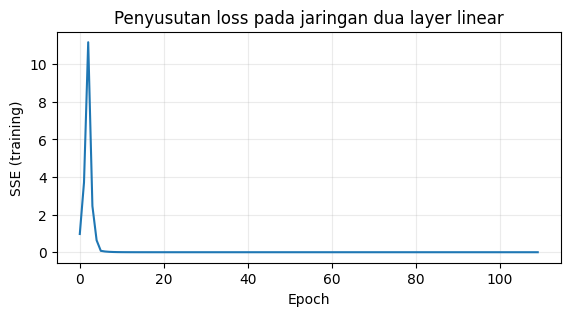

In [10]:
class MSELoss(Layer):
    def __init__(self, reduction='sum'):
        if reduction not in ('sum', 'mean'):
            raise ValueError('reduction harus sum atau mean')
        self.reduction = reduction

    def forward(self, pred, target):
        diff = pred - target
        total = (diff * diff).sum()
        if self.reduction == 'mean':
            return total * (1.0 / diff.data.size)
        return total

model_reg = Sequential([Linear(2, 3), Linear(3, 1)])
criterion_mse = MSELoss(reduction='sum')
optim_reg = SGD(model_reg.get_parameters(), alpha=0.07)
history_reg = []
for epoch in range(110):
    optim_reg.zero_grad()
    loss = criterion_mse.forward(model_reg.forward(X), y)
    loss.backward()
    optim_reg.step()
    history_reg.append(float(loss.data))
print('Loss regresi pertama / terakhir:', round(history_reg[0], 5), '/', round(history_reg[-1], 5))
assert history_reg[-1] < history_reg[0]

plt.figure(figsize=(6.5, 3))
plt.plot(history_reg)
plt.xlabel('Epoch'); plt.ylabel('SSE (training)')
plt.title('Penyusutan loss pada jaringan dua layer linear')
plt.grid(alpha=0.25)
plt.show()

## 13. Nonlinearitas: sigmoid dan tanh 

Komposisi transformasi linear **tanpa fungsi aktivasi nonlinear** tetap ekuivalen dengan satu transformasi linear (abaikan batasan optimisasi). Fungsi aktivasi memperbesar kelas fungsi yang dapat didekati model:

$$\sigma(x)=\frac{1}{1+e^{-x}},\qquad\tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}.$$

- `sigmoid` memetakan bilangan ke $(0,1)$, sering dipakai untuk probabilitas kelas biner (dengan syarat loss sesuai).
- `tanh` memetakan bilangan ke $(-1,1)$, berguna pada state tersembunyi, namun pada magnitudo besar dapat mengalami **vanishing gradient**.

Pada *backward*, $\sigma'(x)=\sigma(x)[1-\sigma(x)]$ dan $\tanh'(x)=1-\tanh^2(x)$. Keduanya sudah diimplementasikan pada `Tensor`.

In [11]:
class Sigmoid(Layer):
    def forward(self, x):
        return x.sigmoid()

class Tanh(Layer):
    def forward(self, x):
        return x.tanh()

val = Tensor([-3., -1., 0., 1., 3.])
print('Sigmoid:', Sigmoid().forward(val).data)
print('Tanh   :', Tanh().forward(val).data)
assert np.all((val.sigmoid().data > 0) & (val.sigmoid().data < 1))

Sigmoid: [0.04743 0.26894 0.5     0.73106 0.95257]
Tanh   : [-0.99505 -0.76159  0.       0.76159  0.99505]


## 14. Mengganti arsitektur tanpa mengubah kode backward 

Latihan berikut menggunakan alur dari buku: `Linear → Tanh → Linear → Sigmoid`. Dataset dan target sama dengan eksperimen sebelumnya. Yang berubah hanyalah daftar layer.

> **Kesimpulan metodologis:** Penurunan *training loss* menunjukkan model dapat mengoptimisasi empat titik yang diberikan, **bukan** bukti kemampuan generalisasi pada populasi atau data lain.

In [12]:
model_nonlin = Sequential([Linear(2, 3), Tanh(), Linear(3, 1), Sigmoid()])
optim_nonlin = SGD(model_nonlin.get_parameters(), alpha=0.9)
history_nonlin = []
for epoch in range(120):
    optim_nonlin.zero_grad()
    loss = criterion_mse.forward(model_nonlin.forward(X), y)
    loss.backward()
    optim_nonlin.step()
    history_nonlin.append(float(loss.data))
print('SSE awal:', round(history_nonlin[0], 5), 'akhir:', round(history_nonlin[-1], 5))
print('Prediksi probabilistik:', model_nonlin.forward(X).data.flatten().round(3))
assert history_nonlin[-1] < history_nonlin[0]

SSE awal: 1.2044 akhir: 0.00236
Prediksi probabilistik: [0.022 0.976 0.026 0.975]


## 15. *Embedding*: dari indeks token menjadi vektor

Dengan vocabulary berukuran $V$ dan dimensi embedding $d$, matriks parameter $E\in\mathbb{R}^{V\times d}$ menyimpan vektor untuk setiap token. Untuk token dengan indeks $i$, hasilnya $E[i]$.

Operasi **`index_select`** berbeda dari perkalian matriks penuh: kita cukup memilih baris relevan. Ketika kata yang sama muncul beberapa kali, gradien untuk baris embedding tersebut harus **diakumulasikan**. Secara teknis hal ini dilakukan menggunakan `np.add.at`.

In [13]:
E = Tensor(np.arange(15.0).reshape(5, 3), autograd=True)
indeks = np.array([1, 2, 1, 4])
selected = E.index_select(indeks)
selected.sum().backward()
print('Hasil lookup:', selected.data)
print('Gradien tiap baris E:', E.grad)
assert np.allclose(E.grad[1], [2., 2., 2.])
assert np.allclose(E.grad[0], 0.0)

class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        weight = rng.uniform(-0.5, 0.5, (vocab_size, dim)) / dim
        self.weight = Tensor(weight, autograd=True)
        self.vocab_size, self.dim = vocab_size, dim

    def forward(self, indices):
        return self.weight.index_select(indices)

    def get_parameters(self):
        return [self.weight]

embed_toy = Embedding(vocab_size=5, dim=4)
print('Bentuk embedding batch:', embed_toy.forward(np.array([1, 2, 1])).data.shape)

Hasil lookup: [[ 3.  4.  5.]
 [ 6.  7.  8.]
 [ 3.  4.  5.]
 [12. 13. 14.]]
Gradien tiap baris E: [[0. 0. 0.]
 [2. 2. 2.]
 [1. 1. 1.]
 [0. 0. 0.]
 [1. 1. 1.]]
Bentuk embedding batch: (3, 4)


## 16. Uji model kecil dengan layer embedding

Buku menggunakan indeks yang berulang, misalnya `[1,2,1,2]`, sebagai latihan untuk melatih embedding. Kita buat tugas dua label sederhana yang memiliki jawaban deterministik. Hal yang harus diperiksa adalah apakah **loss turun** dan apakah **embedding menerima gradien**.

In [14]:
indeks_toy = np.array([1, 2, 1, 2])
label_toy = Tensor(np.array([[0.], [1.], [0.], [1.]]))
model_embed = Sequential([Embedding(3, 3), Tanh(), Linear(3, 1), Sigmoid()])
optim_embed = SGD(model_embed.get_parameters(), alpha=0.5)
loss_embed = []
for epoch in range(180):
    optim_embed.zero_grad()
    output = model_embed.forward(indeks_toy)
    loss = criterion_mse.forward(output, label_toy)
    loss.backward()
    optim_embed.step()
    loss_embed.append(float(loss.data))
print('SSE embedding:', round(loss_embed[0], 5), '->', round(loss_embed[-1], 5))
print('Prediksi:', model_embed.forward(indeks_toy).data.ravel().round(3))
assert loss_embed[-1] < loss_embed[0]

SSE embedding: 1.07376 -> 0.00131
Prediksi: [0.018 0.982 0.018 0.982]


## 17. *Cross entropy*: softmax dan negative log-likelihood 

Untuk $K$ kelas, network menghasilkan **logit** $z_{ik}$ (belum berbentuk probabilitas). Probabilitas kelas diperoleh dari softmax:

$$p_{ik}=\frac{e^{z_{ik}}}{\sum_{j=1}^K e^{z_{ij}}}.$$

Untuk label kelas benar $t_i$ pada sampel ke-$i$, **mean cross-entropy** adalah:

$$L=-\frac{1}{N}\sum_{i=1}^{N}\log p_{i,t_i}.$$

Turunannya terhadap logit adalah $\partial L/\partial z_{ik}=(p_{ik}-\mathbb{1}[k=t_i])/N$. Softmax dan loss digabung menjadi satu fungsi agar lebih stabil dan efisien. Kita mengurangi logit maksimum sebelum eksponensiasi untuk mengurangi risiko *overflow*.

**Catatan koreksi eksplisit:** Contoh gradien buku menggunakan $p-y_{onehot}$ walaupun loss dihitung dengan `.mean()`; notebook ini membagi dengan $N$ agar persis sesuai definisi **mean cross-entropy**. Karena itu skala gradien/loss pelatihan tidak harus persis sama dengan keluaran numerik buku.

In [15]:
logits_besar = Tensor([[1000., 999., -1200.], [-1000., -1001., -999.]], autograd=True)
label_besar = np.array([0, 2])
ce = logits_besar.cross_entropy(label_besar)
ce.backward()
print('Cross entropy finite:', float(ce.data))
print('Gradien logits:', logits_besar.grad)
assert np.isfinite(ce.data)
assert np.all(np.isfinite(logits_besar.grad))
assert np.allclose(logits_besar.grad.sum(axis=1), 0, atol=1e-10)

class CrossEntropyLoss(Layer):
    def forward(self, logits, target_indices):
        return logits.cross_entropy(target_indices)

Cross entropy finite: 0.36043382598130164
Gradien logits: [[-0.13447  0.13447  0.     ]
 [ 0.12236  0.04502 -0.16738]]


## 18. Klasifikasi multiclass dengan `Embedding → Tanh → Linear` 

**Eksperimen reproduksi konsep:** dua indeks input (`1` dan `2`) dipetakan menjadi label `0` dan `1`, tetapi jaringan punya tiga kelas output. Ini menunjukkan bahwa argumen `target` dalam `CrossEntropyLoss` cukup berupa **indeks kelas**, bukan vektor one-hot.

In [16]:
model_ce = Sequential([Embedding(3, 3), Tanh(), Linear(3, 3)])
optim_ce = SGD(model_ce.get_parameters(), alpha=0.15)
criterion_ce = CrossEntropyLoss()
y_ce = np.array([0, 1, 0, 1])
riwayat_ce = []
for epoch in range(130):
    optim_ce.zero_grad()
    logits = model_ce.forward(indeks_toy)
    loss = criterion_ce.forward(logits, y_ce)
    loss.backward()
    optim_ce.step()
    riwayat_ce.append(float(loss.data))
proba_logits = model_ce.forward(indeks_toy).data
prediksi_ce = proba_logits.argmax(axis=1)
print('Cross-entropy:', round(riwayat_ce[0], 5), '->', round(riwayat_ce[-1], 5))
print('Label benar:', y_ce, '| prediksi:', prediksi_ce)
assert riwayat_ce[-1] < riwayat_ce[0]

Cross-entropy: 0.97361 -> 0.02355
Label benar: [0 1 0 1] | prediksi: [0 1 0 1]


## 19. Membuat `RNNCell` dari layer yang sudah ada 

RNN memproses data berurutan dengan cara membawa **hidden state** antarlangkah waktu:

$$h_t=\phi(x_t W_{ih}+h_{t-1}W_{hh}+b),\qquad o_t=h_tW_{ho}+c.$$

Dalam contoh ini, $\phi$ dapat berupa `tanh` atau `sigmoid`. Kita membutuhkan tiga layer linear: **input-to-hidden**, **hidden-to-hidden**, dan **hidden-to-output**. Semua turunan sepanjang urutan dihitung autograd tanpa implementasi *BPTT* manual, karena graf antar-*timestep* tersambung melalui `hidden`.

**Batasan:** Sel ini adalah **RNN biasa**, bukan LSTM. Untuk sekuens panjang, gradien dapat menghilang atau meledak. LSTM menjadi fokus Bab 14.

In [17]:
class RNNCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output, activation='tanh'):
        self.n_inputs = n_inputs
        self.n_hidden = n_hidden
        self.n_output = n_output
        if activation == 'tanh':
            self.activation = Tanh()
        elif activation == 'sigmoid':
            self.activation = Sigmoid()
        else:
            raise ValueError('Aktivasi tidak dikenal: ' + activation)
        self.w_ih = Linear(n_inputs, n_hidden)
        self.w_hh = Linear(n_hidden, n_hidden)
        self.w_ho = Linear(n_hidden, n_output)

    def get_parameters(self):
        return (self.w_ih.get_parameters() + self.w_hh.get_parameters()
                + self.w_ho.get_parameters())

    def init_hidden(self, batch_size=1):
        return Tensor(np.zeros((batch_size, self.n_hidden)))

    def forward(self, x, hidden):
        new_hidden = self.activation.forward(self.w_ih.forward(x) + self.w_hh.forward(hidden))
        output = self.w_ho.forward(new_hidden)
        return output, new_hidden

rnn_uji = RNNCell(4, 5, 3)
y_uji, h_uji = rnn_uji.forward(Tensor(np.ones((2, 4))), rnn_uji.init_hidden(2))
print('Output shape:', y_uji.data.shape, '| Hidden shape:', h_uji.data.shape)
assert y_uji.data.shape == (2, 3) and h_uji.data.shape == (2, 5)

Output shape: (2, 3) | Hidden shape: (2, 5)


## 20. Dataset latihan sekuens 

Buku menggunakan **bAbI task 1** dan melatih RNN pada konteks token pertama hingga kelima untuk memprediksi token keenam. Agar notebook dapat dijalankan tanpa jaringan atau unduhan dataset, kita membuat **dataset demonstrasi sintetis** dengan bentuk enam token:

`['-', nama, kata_kerja, 'to', 'the', lokasi]`

Label lokasi dibuat **deterministik berdasarkan nama**. Ini disengaja untuk uji apakah framework mampu mempelajari suatu pola, **bukan** untuk mengukur kemampuan bahasa alami. Setiap nama dipakai dengan beberapa kata kerja, sementara kombinasi nama–kata kerja lainnya ditahan sebagai data uji; **semua nama dan kata kerja tetap muncul pada data latih**. Tidak ada kalimat identik dalam latih dan uji.

**Potensi kelemahan:** Kosakata, aturan kalimat, dan hubungan nama→lokasi sudah ditentukan; pencapaian akurasi tinggi pada tugas ini tidak boleh digeneralisasi ke teks IMDB atau korpus Shakespeare. Bahkan baseline non-neural yang hanya mengingat nama→lokasi bisa menyelesaikan tugas ini.

In [18]:
nama_lokasi = {
    'mary': 'kitchen', 'john': 'office', 'sandra': 'hallway', 'daniel': 'garden',
    'bill': 'bedroom', 'fred': 'bathroom', 'julie': 'school', 'anna': 'park'
}
verbs = ['moved', 'travelled', 'walked', 'journeyed', 'went', 'returned']

train_sentences, test_sentences = [], []
for person_idx, (name, location) in enumerate(nama_lokasi.items()):
    for k, verb in enumerate(verbs):
        example = ['-', name, verb, 'to', 'the', location]
        # Setiap nama punya 4 train dan 2 test; semua verb muncul pada train.
        (test_sentences if (k + person_idx) % 3 == 0 else train_sentences).append(example)

vocab = sorted({token for seq in train_sentences + test_sentences for token in seq})
w2i = {w: i for i, w in enumerate(vocab)}
i2w = {i: w for w, i in w2i.items()}

train_ids = np.array([[w2i[w] for w in seq] for seq in train_sentences], dtype=int)
test_ids = np.array([[w2i[w] for w in seq] for seq in test_sentences], dtype=int)
print('Train:', train_ids.shape, 'Test:', test_ids.shape, 'Vocabulary:', len(vocab))
print('Contoh sekuens:', train_sentences[0])
print('Target prediksi:', train_sentences[0][-1])
assert train_ids.shape[1] == test_ids.shape[1] == 6
assert len(train_sentences) == len(set(map(tuple, train_sentences)))
assert not (set(map(tuple, train_sentences)) & set(map(tuple, test_sentences)))

Train: (32, 6) Test: (16, 6) Vocabulary: 25
Contoh sekuens: ['-', 'mary', 'travelled', 'to', 'the', 'kitchen']
Target prediksi: kitchen


## 21. Pelatihan RNN untuk prediksi kata keenam 

Pada setiap *epoch*, kita menginisialisasi $h_0=0$, meneruskan **lima token konteks** secara berurutan, lalu menggunakan `CrossEntropyLoss` antara logit langkah kelima dan indeks token keenam. Semua parameter `Embedding` dan `RNNCell` dilatih bersama.

Metrik evaluasi: (1) **mean cross entropy** dan (2) **accuracy prediksi token keenam**. Akurasi dinilai pada pasangan nama-kata kerja yang tidak identik dengan data latih, tetapi seluruh tokennya sudah pernah muncul dalam pelatihan. Namun karena nama-lokasi tetap, tugas ini masih sangat mudah dan tidak menyimulasikan generalisasi ke struktur kalimat baru.

In [19]:
rnn_embed = Embedding(len(vocab), 10)
rnn_model = RNNCell(n_inputs=10, n_hidden=18, n_output=len(vocab), activation='tanh')
param_rnn = rnn_embed.get_parameters() + rnn_model.get_parameters()
optim_rnn = SGD(param_rnn, alpha=0.13)


def logits_sekuens(data_ids):
    hidden = rnn_model.init_hidden(batch_size=len(data_ids))
    for t in range(5):
        x_t = rnn_embed.forward(data_ids[:, t])
        logits, hidden = rnn_model.forward(x_t, hidden)
    return logits

history_train, history_test, acc_test = [], [], []
for epoch in range(251):
    optim_rnn.zero_grad()
    logits = logits_sekuens(train_ids)
    train_loss = criterion_ce.forward(logits, train_ids[:, 5])
    train_loss.backward()                 # BPTT otomatis sampai embedding dan bobot recurrent
    optim_rnn.step()

    if epoch % 10 == 0:
        eval_logits = logits_sekuens(test_ids)
        valid_loss = criterion_ce.forward(eval_logits, test_ids[:, 5])
        accuracy = np.mean(eval_logits.data.argmax(axis=1) == test_ids[:, 5])
        history_train.append((epoch, float(train_loss.data)))
        history_test.append((epoch, float(valid_loss.data)))
        acc_test.append((epoch, float(accuracy)))
        if epoch % 50 == 0:
            print(f'Epoch {epoch:3d} | train CE {float(train_loss.data):.4f} | '
                  f'test CE {float(valid_loss.data):.4f} | test accuracy {accuracy:.1%}')

assert np.isfinite(history_train[-1][1])
assert history_train[-1][1] < history_train[0][1]

Epoch   0 | train CE 3.2355 | test CE 3.1009 | test accuracy 12.5%
Epoch  50 | train CE 1.0017 | test CE 1.0546 | test accuracy 75.0%
Epoch 100 | train CE 0.3132 | test CE 0.3475 | test accuracy 100.0%
Epoch 150 | train CE 0.1191 | test CE 0.1325 | test accuracy 100.0%


Epoch 200 | train CE 0.0680 | test CE 0.0744 | test accuracy 100.0%


Epoch 250 | train CE 0.0462 | test CE 0.0500 | test accuracy 100.0%


## 22. Membaca kurva pelatihan, akurasi, dan contoh prediksi

*Training loss* seharusnya menurun pada data demonstrasi. Namun jangan hanya menilai *training loss*: kurva evaluasi menampakkan apakah pola yang dipelajari juga digunakan pada kombinasi yang ditahan saat pelatihan.

Untuk menghindari interpretasi berlebihan, bandingkan RNN dengan dua baseline: prediksi kelas terbanyak dan aturan lookup nama→lokasi dari data latih. Jika aturan lookup mencapai hasil serupa, kompleksitas RNN belum terbukti diperlukan.

Jika hasil berbeda antarlingkungan, periksa *random seed*, *learning rate*, inisialisasi bobot, serta tipe data. Ketidakstabilan adalah bagian dari evaluasi implementasi neural network, bukan alasan untuk hanya melaporkan hasil terbaik.

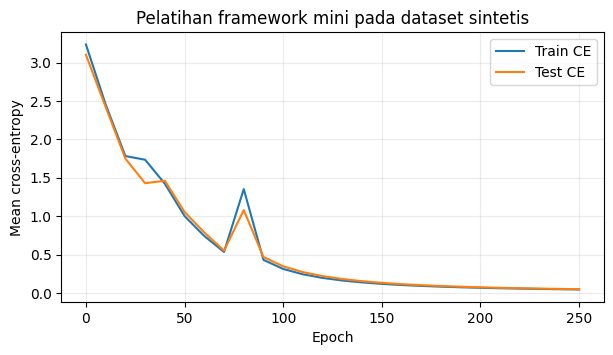

Evaluasi akhir: accuracy = 100.0%
- mary moved to the                    | benar=kitchen   | pred=kitchen
- mary journeyed to the                | benar=kitchen   | pred=kitchen
- john walked to the                   | benar=office    | pred=office
- john returned to the                 | benar=office    | pred=office
- sandra travelled to the              | benar=hallway   | pred=hallway
- sandra went to the                   | benar=hallway   | pred=hallway
Baseline mayoritas: 12.5%; baseline lookup nama: 100.0%


In [20]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([r[0] for r in history_train], [r[1] for r in history_train], label='Train CE')
ax.plot([r[0] for r in history_test], [r[1] for r in history_test], label='Test CE')
ax.set_xlabel('Epoch'); ax.set_ylabel('Mean cross-entropy')
ax.set_title('Pelatihan framework mini pada dataset sintetis')
ax.grid(alpha=0.25); ax.legend()
plt.show()

pred_ids = logits_sekuens(test_ids).data.argmax(axis=1)
print('Evaluasi akhir: accuracy =', f'{np.mean(pred_ids == test_ids[:, 5]):.1%}')
for i in range(min(6, len(test_ids))):
    context = ' '.join(i2w[t] for t in test_ids[i, :5])
    print(f'{context:38s} | benar={i2w[test_ids[i, 5]]:9s} | pred={i2w[pred_ids[i]]}')

# Baseline mayoritas dan model non-neural sederhana: lookup nama -> lokasi.
values, counts = np.unique(train_ids[:, 5], return_counts=True)
majority_id = values[np.argmax(counts)]
majority_acc = np.mean(test_ids[:, 5] == majority_id)
name_to_location = {int(seq[1]): int(seq[5]) for seq in train_ids}
lookup_preds = np.array([name_to_location[int(seq[1])] for seq in test_ids])
lookup_acc = np.mean(lookup_preds == test_ids[:, 5])
print(f'Baseline mayoritas: {majority_acc:.1%}; baseline lookup nama: {lookup_acc:.1%}')
assert set(test_ids[:, 2]).issubset(set(train_ids[:, 2]))

In [21]:
from pathlib import Path

def load_babi_excerpt(path, limit=1000, length=6):
    p = Path(path)
    if not p.is_file():
        return None
    sequences = []
    for line in p.read_text(encoding='utf-8').splitlines()[:limit]:
        # Format standar: "1 Mary moved to the bathroom."
        parts = line.strip().lower().split(maxsplit=1)
        if len(parts) < 2:
            continue
        words = parts[1].split()
        if 1 <= len(words) <= length and not ('?' in parts[1] or '	' in parts[1]):
            sequences.append(['-'] * (length - len(words)) + words)
    return sequences

babi_path = Path('tasksv11/en/qa1_single-supporting-fact_train.txt')
babi_excerpt = load_babi_excerpt(babi_path)
if babi_excerpt is None:
    print('Dataset bAbI tidak tersedia secara lokal. Eksperimen sintetis tetap berjalan lengkap.')
else:
    print('Baris bAbI yang memenuhi filter:', len(babi_excerpt))
    print('Contoh pertama:', babi_excerpt[0] if babi_excerpt else '(kosong)')

Dataset bAbI tidak tersedia secara lokal. Eksperimen sintetis tetap berjalan lengkap.


## 24. Evaluasi kritis: apa yang benar-benar direproduksi?

| Bagian Bab 13 | Implementasi notebook ini | Status dan batasan |
|---|---|---|
| Tensor dan graf dinamis (233–236) | `Tensor`, `creators`, `creation_op` | Ya, implementasi ulang |
| Gradien dari tensor multiuse (237–240) | Reverse topological traversal | Ya, hasil matematis setara; strategi berbeda dari buku |
| Add, neg, sub, mul, sum, expand, transpose, mm (240–245) | Semua operasi dan gradien lokal | Ya, termasuk gradien broadcasting |
| Autograd untuk neural network (246–247) | Dua transformasi linear | Ya, dataset contoh yang sama |
| Optimizer, layer, loss (248–252) | `SGD`, `Linear`, `Sequential`, `MSELoss` | Ya, disertai pembedaan SSE/MSE |
| Nonlinearitas (253–254) | `Tanh`, `Sigmoid` | Ya |
| Embedding dan indexing (255–257) | `Embedding`, `index_select` | Ya, diuji untuk token berulang |
| Cross-entropy (258–259) | Softmax + mean NLL stabil | Ya; gradien diperbaiki sesuai normalisasi batch |
| RNNCell (260–263) | `RNNCell` dan pelatihan sekuens | Ya, dataset sintetis, **bukan** metrik bAbI buku |

### Kesalahan umum yang diuji

1. **Gradien timpa:** ketika parameter dipakai dua kali, gradien harus dijumlahkan.
2. **Urutan transpose salah:** pada `C=A@B`, gradien $A$ dan $B$ harus mempertahankan bentuk aslinya.
3. **Softmax overflow:** jangan langsung memanggil `exp(logit)` jika nilainya dapat ekstrem.
4. **Kesalahan normalisasi:** gradien dari *mean cross entropy* mengandung faktor $1/N$.
5. **Data leakage:** memisahkan data latih dan uji tidak cukup jika generator keduanya memiliki aturan yang sangat mudah; interpretasi evaluasi harus hati-hati.

**Tingkat keyakinan:** **tinggi** bahwa operasi yang diuji memenuhi rumus turunan lokal pada kasus demonstrasi, karena cocok dengan *finite-difference gradient checks*. **Terbatas** untuk klaim kinerja umum, karena dataset kecil dan sintetis serta tidak ada benchmark independen di buku yang direplikasi secara identik.

## 25. Rangkuman Bab 13

Bab 13 memindahkan perhatian dari **menulis gradien secara manual** menuju **membangun infrastruktur pembelajaran otomatis**. Intinya:

- `Tensor` menyimpan nilai numerik dan dependensi operasi.
- **Autograd** menerapkan *chain rule* secara terbalik, termasuk ketika satu parameter dipakai berkali-kali.
- `Layer` membuat blok neural network dapat digunakan ulang; `Sequential` menyusunnya; `SGD` memperbarui parameternya.
- `Embedding`, `CrossEntropyLoss`, dan `RNNCell` menunjukkan bahwa model berurutan dapat dibangun dari komponen yang sama tanpa menuliskan BPTT manual.
- **Evaluasi kualitas model** tetap membutuhkan dataset yang relevan, pemisahan data yang tepat, baseline, serta pengujian numerik; keberhasilan *toy example* tidak otomatis berimplikasi pada tugas dunia nyata.